In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import os

print(os.getcwd())
print(os.listdir())

C:\Users\Admin\Desktop\Installations\AIML
['.ipynb_checkpoints', 'amazon_store_data.json', 'employee_data.csv', 'IRIS.csv', 'NumPy .pdf', 'numpy_tutorial.ipynb', 'oops_concepts.ipynb', 'Pandas Notes.pdf', 'pandas_tutorial.ipynb', 'python_basics.ipynb', 'raw_data.csv', 'retail_sales.ipynb', 'retail_sales_dataset.csv', 'thinking_data.ipynb', 'Titanic-Dataset.csv']


In [4]:
df=pd.read_csv("retail_sales_dataset.csv")

In [5]:
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [7]:
print(df.shape)

(1000, 9)


In [9]:
print(df.columns)

Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='str')


In [10]:
print(df.dtypes)

Transaction ID      int64
Date                  str
Customer ID           str
Gender                str
Age                 int64
Product Category      str
Quantity            int64
Price per Unit      int64
Total Amount        int64
dtype: object


In [11]:
df['Date'] = pd.to_datetime(df['Date'])

In [12]:
df.dtypes

Transaction ID               int64
Date                datetime64[us]
Customer ID                    str
Gender                         str
Age                          int64
Product Category               str
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object

In [32]:
print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())


Missing values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
Age Group           0
dtype: int64

Duplicate rows: 0


In [13]:
df.describe()

,Transaction ID,Date,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,2023-07-03 00:25:55.200000,41.39200,2.514000,179.890000,456.000000
min,1.000000,2023-01-01 00:00:00,18.00000,1.000000,25.000000,25.000000
25%,250.750000,2023-04-08 00:00:00,29.00000,1.000000,30.000000,60.000000
50%,500.500000,2023-06-29 12:00:00,42.00000,3.000000,50.000000,135.000000
75%,750.250000,2023-10-04 00:00:00,53.00000,4.000000,300.000000,900.000000
max,1000.000000,2024-01-01 00:00:00,64.00000,4.000000,500.000000,2000.000000
std,288.819436,NaN,13.68143,1.132734,189.681356,559.997632


In [31]:
numeric_df = df.select_dtypes(include='number')

print("Mean:")
print(numeric_df.mean())

print("\nMedian:")
print(numeric_df.median())

print("\nMode:")
print(numeric_df.mode().iloc[0])

print("\nStandard Deviation:")
print(numeric_df.std())

Mean:
Transaction ID    500.500
Age                41.392
Quantity            2.514
Price per Unit    179.890
Total Amount      456.000
dtype: float64

Median:
Transaction ID    500.5
Age                42.0
Quantity            3.0
Price per Unit     50.0
Total Amount      135.0
dtype: float64

Mode:
Transaction ID     1.0
Age               43.0
Quantity           4.0
Price per Unit    50.0
Total Amount      50.0
Name: 0, dtype: float64

Standard Deviation:
Transaction ID    288.819436
Age                13.681430
Quantity            1.132734
Price per Unit    189.681356
Total Amount      559.997632
dtype: float64


In [14]:
numeric_df = df.select_dtypes(include='number')

print("Median:")
print(numeric_df.median())

print("\nMode:")
print(numeric_df.mode().iloc[0])

Median:
Transaction ID    500.5
Age                42.0
Quantity            3.0
Price per Unit     50.0
Total Amount      135.0
dtype: float64

Mode:
Transaction ID     1.0
Age               43.0
Quantity           4.0
Price per Unit    50.0
Total Amount      50.0
Name: 0, dtype: float64


In [15]:
monthly_sales = df.groupby(df['Date'].dt.to_period('M'))['Total Amount'].sum()

monthly_sales

Date
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64

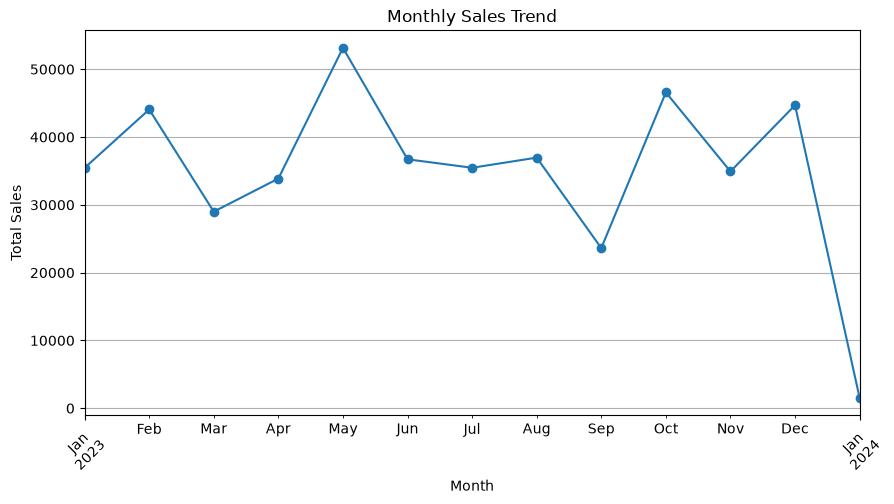

In [16]:
monthly_sales.plot(kind='line', marker='o', figsize=(10, 5))

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

### Observation

Monthly sales fluctuated throughout 2023. The highest sales were recorded in May 2023, with total sales of 53,150, while the lowest sales were recorded in September 2023, with 23,620. Sales increased again in October and December. The sharp decrease in January 2024 may be due to the dataset containing only partial-month data.

In [17]:
quarterly_sales = df.groupby(df['Date'].dt.to_period('Q'))['Total Amount'].sum()

quarterly_sales

Date
2023Q1    108500
2023Q2    123735
2023Q3     96045
2023Q4    126190
2024Q1      1530
Freq: Q-DEC, Name: Total Amount, dtype: int64

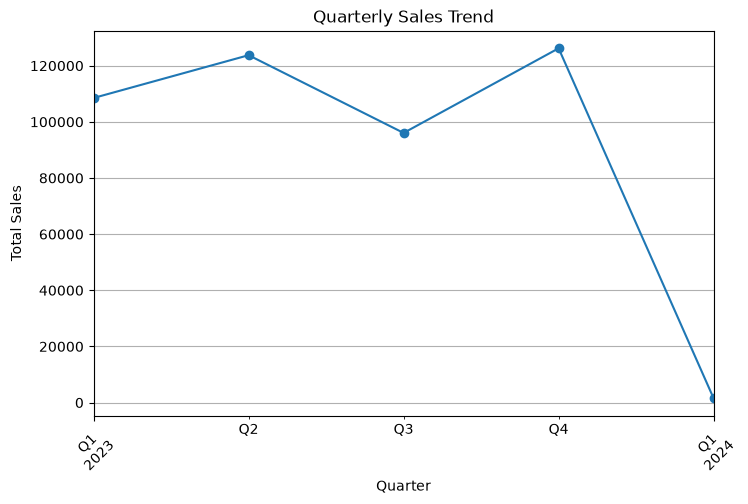

In [18]:
quarterly_sales.plot(kind='line', marker='o', figsize=(8, 5))

plt.title('Quarterly Sales Trend')
plt.xlabel('Quarter')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

### Observation

Quarterly sales varied during the period. The highest sales were recorded in the fourth quarter of 2023, with total sales of 126,190. The third quarter had the lowest sales among the complete quarters of 2023, with 96,045. The first quarter of 2024 shows only 1,530 in sales, which may be because the dataset contains incomplete data for that quarter.

In [19]:
df['Age Group'] = pd.cut(
    df['Age'],
    bins=[0, 18, 30, 45, 60, 100],
    labels=['Below 18', '18–30', '31–45', '46–60', 'Above 60']
)

In [20]:
df['Age Group'].value_counts().sort_index()

Age Group
Below 18     21
18–30       252
31–45       303
46–60       331
Above 60     93
Name: count, dtype: int64

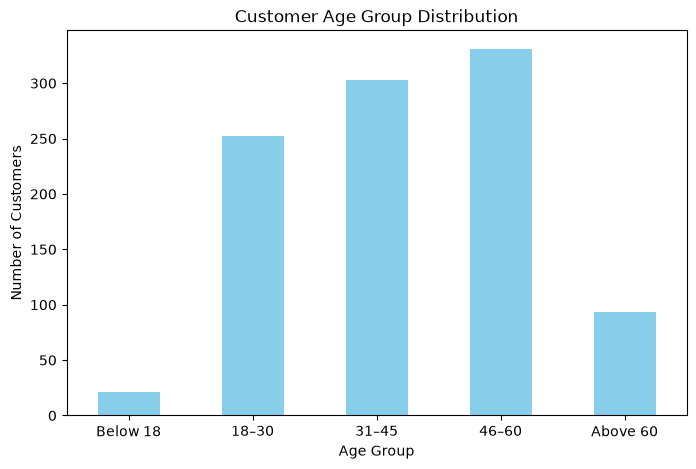

In [21]:
df['Age Group'].value_counts().sort_index().plot(
    kind='bar',
    color='skyblue',
    figsize=(8, 5)
)

plt.title('Customer Age Group Distribution')
plt.xlabel('Age Group')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.show()

### Observation

The gender distribution is almost balanced. The dataset contains 510 female customers and 490 male customers. This indicates that both genders contribute nearly equally to the customer base.

In [22]:
df['Gender'].value_counts()

Gender
Female    510
Male      490
Name: count, dtype: int64

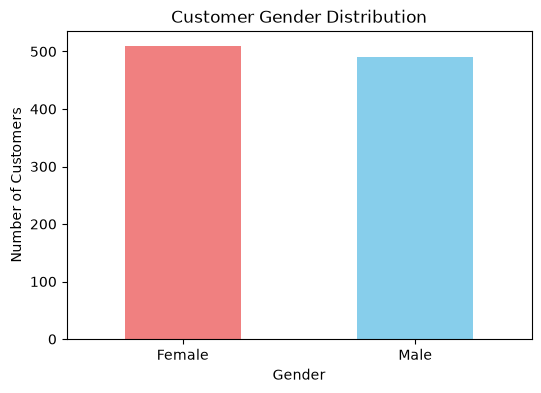

In [23]:
df['Gender'].value_counts().plot(
    kind='bar',
    color=['lightcoral', 'skyblue'],
    figsize=(6, 4)
)

plt.title('Customer Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.show()

### Observation

The gender distribution is almost balanced. The dataset contains 510 female customers and 490 male customers. This indicates that both genders contribute nearly equally to the customer base.

In [24]:
category_sales = df.groupby('Product Category')['Total Amount'].sum()

category_sales

Product Category
Beauty         143515
Clothing       155580
Electronics    156905
Name: Total Amount, dtype: int64

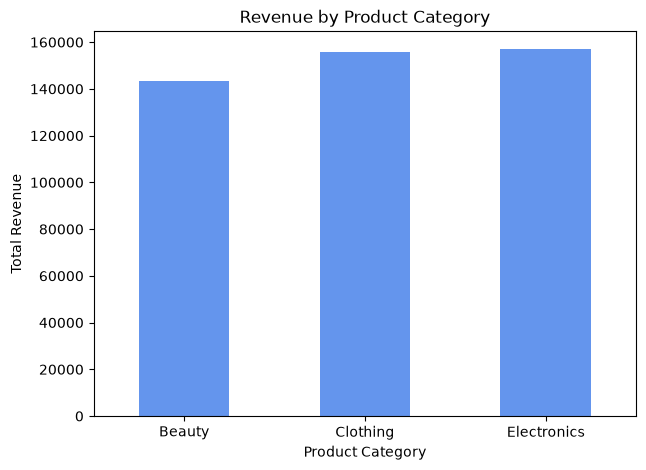

In [25]:
category_sales.plot(
    kind='bar',
    color='cornflowerblue',
    figsize=(7, 5)
)

plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)
plt.show()

### Observation

Electronics generated the highest revenue, with 156,905, followed closely by Clothing, with 155,580. Beauty generated the lowest revenue, with 143,515. Overall, revenue is relatively balanced across the three product categories.

In [26]:
df.columns

Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount',
       'Age Group'],
      dtype='str')

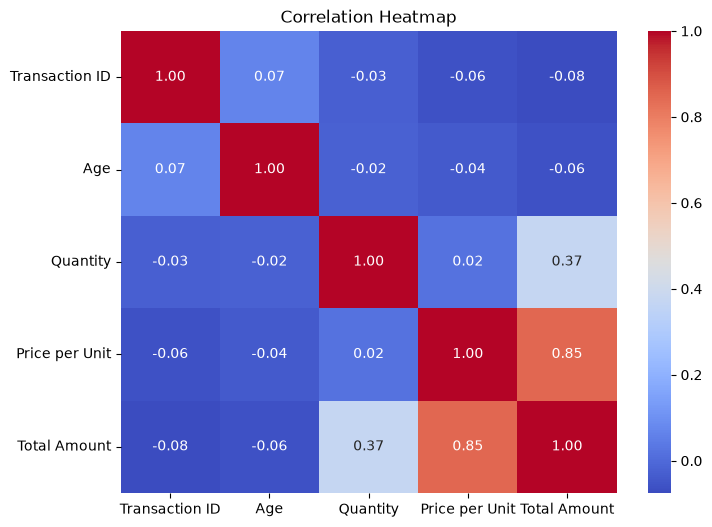

In [27]:
numeric_df = df.select_dtypes(include='number')

correlation = numeric_df.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')
plt.show()

### Observation

The correlation heatmap shows the relationships between numerical variables in the dataset. Quantity and Total Amount are expected to have a positive relationship because purchasing more items generally increases the total bill. The heatmap helps identify patterns among numerical variables; however, correlation does not prove that one variable causes another.

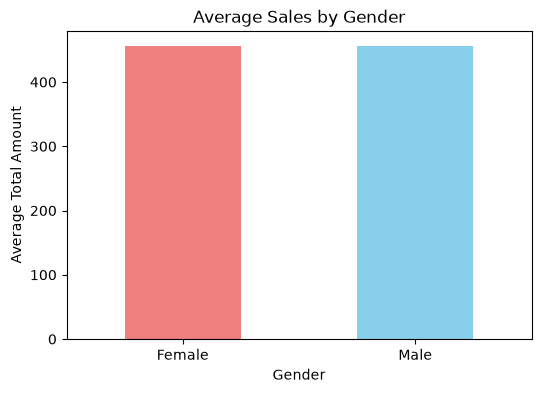

In [28]:
gender_sales = df.groupby('Gender')['Total Amount'].mean()

gender_sales.plot(kind='bar', color=['lightcoral', 'skyblue'], figsize=(6, 4))

plt.title('Average Sales by Gender')
plt.xlabel('Gender')
plt.ylabel('Average Total Amount')
plt.xticks(rotation=0)
plt.show()

### Observation

The average total sales for female and male customers are almost equal. This suggests that both genders spend a similar amount on average in this dataset. Therefore, marketing strategies may consider both groups rather than focusing strongly on one gender.

## Conclusion

This exploratory data analysis was performed on a retail sales dataset containing 1,000 transactions. The dataset had no missing values or duplicate records, making it suitable for the analysis.

The analysis showed that customers aged 46–60 years formed the largest age group. The gender distribution was nearly balanced, with 510 female customers and 490 male customers.

Among the product categories, Electronics generated the highest revenue, followed closely by Clothing. Monthly and quarterly sales fluctuated throughout the dataset, with the fourth quarter of 2023 recording the highest quarterly revenue. The additional visualization showed that average spending was almost equal for female and male customers.

### Business Recommendations

1. **Target the 46–60 age group:** Create targeted offers and promotions for this large customer segment to encourage more purchases.
2. **Maintain strong Electronics and Clothing inventory:** These categories generated the highest revenue. Monitor stock levels and consider suitable promotions to maintain sales.
3. **Improve sales during slower periods:** Investigate low-sales months, such as September 2023, and introduce seasonal campaigns or discounts to encourage purchases.

### Limitation

The dataset contains product categories but does not include individual product names. Therefore, a top 10 best-selling individual-products analysis could not be performed. Instead, revenue was analyzed by product category.